# LGG MRI segmentation: baseline vs sequence-dropout (resumable, free-Kaggle-GPU friendly)

**How to use**
- **Settings → Accelerator → GPU T4 x2**, Internet off is fine. Add input: `mateuszbuda/lgg-mri-segmentation`.
- You can press **Run All** at any time. Every step first checks whether its result already exists and skips itself in seconds if so.
- Cells run strictly top to bottom and **each cell blocks until it is finished**. Cell 5 (training) only returns when all 6 runs are done, so Cell 6 cannot start early. If a cell's input is missing, it stops with a clear error telling you which cell to run.
- After a kernel restart or a stopped session: run **Cell 1**, then any later cell. Data is reloaded from `/kaggle/working/cache` (seconds), nothing is recomputed.
- Interrupted training continues from the last finished epoch (`resume.pt`), not from epoch 1.
- To survive switching your PC off: **Save Version -> Save & Run All (Commit)**. It runs on Kaggle's servers. Next time add that notebook's *output* as an input; Cell 1 restores cache, split and finished runs automatically.
- Interactive session: press **Stop session** when you are done, otherwise the GPU quota keeps counting.

| Cell | What it does | Normal cost |
|---|---|---|
| 1 | settings, helpers, restore earlier output | seconds |
| 2 | read tif files once, patient-level split | skipped if done, else 1-6 min (CPU) |
| 3 | write `lgg_seg.py` (model, losses, metrics, resumable training) | instant |
| 4 | build npy cache, load data, sanity checks | skipped/seconds |
| 5 | train 6 runs on the 2 GPUs (resumable) | about 1.5 h first time, seconds if finished |
| 6 | test evaluation + stats (saved to CSV) | about 2 min first time, seconds afterwards |
| 7 | side-by-side figure | seconds |
| 8 | wrap-up | instant |

In [1]:
# ===== Cell 1: settings, helper functions, restore earlier output (fast, safe to re-run any time) =====
import os, sys, glob, platform, json, time, hashlib, importlib, shutil, subprocess, shlex
import numpy as np, pandas as pd, torch, sklearn, PIL

WORK_DIR = "/kaggle/working"
CACHE  = f"{WORK_DIR}/cache"
BASE   = f"{WORK_DIR}/runs/stage3"
INDEX  = f"{WORK_DIR}/lgg_index.csv"
MODULE = f"{WORK_DIR}/lgg_seg.py"
SEED = 42
EXPECTED_FP = "214d478caf1818662c0076ab66518de9"   # fingerprint of the patient-level split used in every experiment
FORCE_EVAL = False     # True -> recompute the Stage-3 test evaluation even when saved results exist
POLL_S = 180           # training cell prints progress every POLL_S seconds

COMMON = dict(base=32, batch_size=16, lr=3e-4, wd=1e-4, epochs=50, patience=12,
              loss="bce", num_workers=2, device="cuda:0")
CONFIGS = {"baseline": dict(p_flair_only=0.0, p_post_missing=0.0),
           "seqdrop":  dict(p_flair_only=0.25, p_post_missing=0.15)}
SEEDS = [42, 43, 44]
SUBST = {"TCGA_DU_6407", "TCGA_DU_7013", "TCGA_DU_7301", "TCGA_DU_8165", "TCGA_FG_7634",
         "TCGA_FG_A60K", "TCGA_HT_7877", "TCGA_HT_8105", "TCGA_HT_A616", "TCGA_HT_A61B"}

print("Python", platform.python_version(), "| torch", torch.__version__, "| sklearn", sklearn.__version__,
      "| numpy", np.__version__, "| PIL", PIL.__version__)
print("GPUs:", [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())] or "none (CPU session)")

DATA_ROOT = "/kaggle/input/datasets/mateuszbuda/lgg-mri-segmentation"
if not os.path.isdir(DATA_ROOT):
    found = sorted({p.split("/kaggle_3m/")[0] for p in
                    glob.glob("/kaggle/input/**/kaggle_3m/data.csv", recursive=True)}, key=len)
    DATA_ROOT = found[0] if found else None
print("DATA_ROOT =", DATA_ROOT or "not attached (fine if cache + split were restored from an earlier output)")
os.makedirs(BASE, exist_ok=True)

# ---------------- helpers ----------------
def need_files(*paths, hint=""):
    """Stop with a clear message when an earlier cell has not produced its result yet."""
    missing = [p for p in paths if not os.path.exists(p)]
    if missing:
        raise RuntimeError("Not ready - missing: " + ", ".join(os.path.relpath(p, WORK_DIR) for p in missing)
                           + (f"\n-> {hint}" if hint else ""))

def split_fingerprint(d):
    pf = d.groupby("patient_id").fold.first()
    return hashlib.md5("".join(f"{p}:{f};" for p, f in sorted(zip(pf.index, pf.values))).encode()).hexdigest()

def running_jobs():
    """Number of training processes (run_one.py) alive right now; also works after a kernel restart."""
    me, n = os.getpid(), 0
    for pid in os.listdir("/proc"):
        if pid.isdigit() and int(pid) != me:
            try:
                cmd = open(f"/proc/{pid}/cmdline", "rb").read().replace(b"\0", b" ").decode(errors="ignore")
            except OSError:
                continue
            if "run_one.py" in cmd:
                n += 1
    return n

def copy_missing(src, dst):
    """Copy files that do not exist yet in dst (never overwrites newer work of this session)."""
    if os.path.isfile(src):
        if not os.path.exists(dst):
            os.makedirs(os.path.dirname(dst), exist_ok=True); shutil.copy2(src, dst)
        return
    for root, _, files in os.walk(src):
        rel = os.path.relpath(root, src)
        out = dst if rel == "." else os.path.join(dst, rel)
        os.makedirs(out, exist_ok=True)
        for f in files:
            d = os.path.join(out, f)
            if not os.path.exists(d):
                shutil.copy2(os.path.join(root, f), d)

def ensure_state(force=False):
    """(Re)creates df, imgs, msks, stats and the module alias L from disk. Every later cell calls this first,
    so after a kernel restart you only need to run Cell 1 and then the cell you want."""
    g = globals()
    need_files(INDEX, MODULE, f"{CACHE}/images.npy", f"{CACHE}/masks.npy", f"{CACHE}/index.csv",
               hint="Run Cells 2-4 first (they are skipped within seconds when already done).")
    if WORK_DIR not in sys.path:
        sys.path.insert(0, WORK_DIR)
    importlib.invalidate_caches()
    if "lgg_seg" in sys.modules and (force or "L" not in g):
        importlib.reload(sys.modules["lgg_seg"])
    g["L"] = importlib.import_module("lgg_seg")
    if force or any(k not in g for k in ("df", "imgs", "msks", "stats")):
        t0 = time.time()
        g["df"], g["imgs"], g["msks"] = g["L"].load_cache(CACHE)
        g["stats"] = g["L"].patient_channel_stats(g["df"], g["imgs"])
        assert split_fingerprint(g["df"]) == EXPECTED_FP, "Cached split differs from the experiment split - stop."
        assert (g["df"].groupby("patient_id").split.nunique() == 1).all()
        print(f"State loaded from cache in {time.time() - t0:.0f}s: {g['imgs'].shape} | "
              + " | ".join(f"{k} {v}" for k, v in g["df"].groupby("split").patient_id.nunique().items()) + " patients")

# ---------------- restore an earlier output (attached as Input) ----------------
prev = sorted({os.path.dirname(p) for p in glob.glob("/kaggle/input/**/lgg_index.csv", recursive=True)}, key=len)
if prev:
    print("Restoring missing files from earlier output:", prev[0])
    for item in ("lgg_index.csv", "splits", "cache", "runs"):
        if os.path.exists(os.path.join(prev[0], item)):
            copy_missing(os.path.join(prev[0], item), os.path.join(WORK_DIR, item))
else:
    print("No earlier output attached -> fresh start (or continuing in the same session).")
fin = sorted(os.path.basename(os.path.dirname(p)) for p in glob.glob(f"{BASE}/*/last.pt"))
print(f"Finished runs available: {len(fin)}/6 {fin}")

Python 3.12.13 | torch 2.10.0+cu128 | sklearn 1.6.1 | numpy 2.0.2 | PIL 11.3.0
GPUs: ['Tesla T4', 'Tesla T4']
DATA_ROOT = /kaggle/input/datasets/mateuszbuda/lgg-mri-segmentation
No earlier output attached -> fresh start (or continuing in the same session).
Finished runs available: 0/6 []


In [2]:
# ===== Cell 2: image index + patient-level split (skipped automatically when already done) =====
import re
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor
from PIL import Image
from sklearn.model_selection import StratifiedKFold

def index_is_valid():
    if not os.path.exists(INDEX):
        return False
    d = pd.read_csv(INDEX)
    if not {"fold", "split", "image_path"} <= set(d.columns) or split_fingerprint(d) != EXPECTED_FP:
        return False
    cache_ok = all(os.path.exists(f"{CACHE}/{n}") for n in ("images.npy", "masks.npy", "index.csv"))
    return cache_ok or os.path.exists(d.image_path.iloc[0])      # paths are only needed while the cache is missing

def build_index_and_split():
    assert DATA_ROOT, "LGG dataset not found: Add Input -> mateuszbuda/lgg-mri-segmentation"
    IMG_RE  = re.compile(r"^(TCGA_[A-Z0-9]+_[A-Z0-9]+)_(\d+)_(\d+)\.tif$")
    MASK_RE = re.compile(r"^(TCGA_[A-Z0-9]+_[A-Z0-9]+)_(\d+)_(\d+)_mask\.tif$")
    t0 = time.time()
    all_tifs = sorted(glob.glob(os.path.join(DATA_ROOT, "**", "*.tif"), recursive=True))
    by_root = defaultdict(list)                       # the Kaggle dataset can be stored twice (identical copies)
    for p in all_tifs:
        by_root[os.path.dirname(os.path.dirname(p))].append(p)
    ROOT = sorted(by_root, key=lambda r: (-len(by_root[r]), len(r)))[0]
    print(f"{len(all_tifs)} tif files | using ROOT = {ROOT}")
    img_paths, mask_paths = {}, {}
    for p in by_root[ROOT]:
        fn = os.path.basename(p)
        m = MASK_RE.match(fn)
        if m: mask_paths[(m.group(1), m.group(2), int(m.group(3)))] = p; continue
        m = IMG_RE.match(fn)
        if m: img_paths[(m.group(1), m.group(2), int(m.group(3)))] = p
    assert set(img_paths) == set(mask_paths), "image/mask pairing is not one-to-one"

    def inspect_pair(key):
        pid, date, sl = key
        im = np.array(Image.open(img_paths[key])); mk = np.array(Image.open(mask_paths[key]))
        mk2 = mk[..., 0] if mk.ndim == 3 else mk
        return dict(patient_id=pid, study_date=date, slice_idx=sl, image_path=img_paths[key], mask_path=mask_paths[key],
                    img_max=int(im.max()), tumor_px=int((mk2 > 0).sum()),
                    ch01_equal=bool(np.array_equal(im[..., 0], im[..., 1])),
                    ch12_equal=bool(np.array_equal(im[..., 1], im[..., 2])),
                    ch02_equal=bool(np.array_equal(im[..., 0], im[..., 2])))
    with ThreadPoolExecutor(16) as ex:
        df = pd.DataFrame(list(ex.map(inspect_pair, sorted(img_paths))))
    df["has_tumor"] = df.tumor_px > 0
    df["institution"] = df.patient_id.str.split("_").str[1]
    print(f"{df.patient_id.nunique()} patients | {len(df)} slices | tumor slices {int(df.has_tumor.sum())} | {time.time() - t0:.0f}s")
    ch = df[df.img_max > 0].groupby("patient_id")[["ch01_equal", "ch12_equal", "ch02_equal"]].mean()
    assert set(ch[(ch > 0.9).any(axis=1)].index) == SUBST, "Substituted-channel patient list changed!"

    pt = df.groupby("patient_id").agg(institution=("institution", "first")).reset_index()
    N_FOLDS, TEST_FOLD, VAL_FOLD = 5, 0, 1
    cnt = pt.institution.value_counts()
    pt["strata"] = np.where(pt.institution.map(cnt) >= N_FOLDS, pt.institution, cnt.index[0])
    pt["fold"] = -1
    for f, (_, te) in enumerate(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(pt.patient_id, pt.strata)):
        pt.loc[te, "fold"] = f
    pt["split"] = np.select([pt.fold == TEST_FOLD, pt.fold == VAL_FOLD], ["test", "val"], "train")
    df = df.merge(pt[["patient_id", "fold", "split"]], on="patient_id", how="left", validate="many_to_one")
    S = {s: set(df.loc[df.split == s, "patient_id"]) for s in ("train", "val", "test")}
    assert not (S["train"] & S["val"]) and not (S["train"] & S["test"]) and not (S["val"] & S["test"])
    fp = split_fingerprint(df)
    assert fp == EXPECTED_FP, "Split differs from the earlier experiments - stop."
    os.makedirs(f"{WORK_DIR}/splits", exist_ok=True)
    pt.to_csv(f"{WORK_DIR}/splits/patient_folds.csv", index=False)
    json.dump(dict(seed=SEED, n_folds=N_FOLDS, test_fold=TEST_FOLD, val_fold=VAL_FOLD, stratify="institution",
                   root=ROOT, split_fingerprint=fp, sklearn=sklearn.__version__),
              open(f"{WORK_DIR}/splits/protocol.json", "w"), indent=2)
    df.to_csv(INDEX, index=False)
    print("Split fingerprint verified; saved", INDEX)

if index_is_valid():
    print("Index + patient-level split already available (fingerprint verified) -> skipped.")
else:
    build_index_and_split()
print(pd.read_csv(INDEX).groupby("split").agg(patients=("patient_id", "nunique"), slices=("slice_idx", "size"),
                                              tumor_slices=("has_tumor", "sum")).to_string())

15716 tif files | using ROOT = /kaggle/input/datasets/mateuszbuda/lgg-mri-segmentation/kaggle_3m
110 patients | 3929 slices | tumor slices 1373 | 35s
Split fingerprint verified; saved /kaggle/working/lgg_index.csv
       patients  slices  tumor_slices
split                                
test         22     767           287
train        66    2387           798
val          22     775           288


In [3]:
%%writefile /kaggle/working/lgg_seg.py
"""LGG FLAIR-abnormality segmentation: caching, data, U-Net, losses, metrics, training, evaluation, plots."""
import os, json, time, random
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, torch, torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage
from torch.utils.data import Dataset, DataLoader
from torchvision import tv_tensors
from torchvision.transforms import v2, InterpolationMode

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

# ---------------- cache ----------------
def _read_pair(paths):
    ip, mp = paths
    im = np.array(Image.open(ip)); mk = np.array(Image.open(mp))
    mk = mk[..., 0] if mk.ndim == 3 else mk
    return im, (mk > 0).astype(np.uint8)

def build_cache(index_csv, cache_dir, n_threads=16):
    os.makedirs(cache_dir, exist_ok=True)
    f_img, f_msk, f_idx = (os.path.join(cache_dir, n) for n in ("images.npy", "masks.npy", "index.csv"))
    if all(os.path.exists(f) for f in (f_img, f_msk, f_idx)):
        print("Cache already exists:", cache_dir); return
    df = pd.read_csv(index_csv).sort_values(["patient_id", "slice_idx"]).reset_index(drop=True)
    assert "split" in df.columns, "Index must contain the split (run Cell 4)."
    imgs = np.empty((len(df), 256, 256, 3), np.uint8); msks = np.empty((len(df), 256, 256), np.uint8)
    t0 = time.time()
    with ThreadPoolExecutor(n_threads) as ex:
        for i, (im, mk) in enumerate(ex.map(_read_pair, zip(df.image_path, df.mask_path))):
            imgs[i], msks[i] = im, mk
    np.save(f_img, imgs); np.save(f_msk, msks); df.to_csv(f_idx, index=False)
    print(f"Cached {len(df)} slices in {time.time() - t0:.0f}s -> {cache_dir}")

def load_cache(cache_dir):
    df = pd.read_csv(os.path.join(cache_dir, "index.csv"))
    return df, np.load(os.path.join(cache_dir, "images.npy")), np.load(os.path.join(cache_dir, "masks.npy"))

def patient_channel_stats(df, imgs):
    """Per-patient, per-channel mean/std (only that patient's own volume -> no cross-split leakage)."""
    stats = np.zeros((len(df), 2, 3), np.float32)
    for _, idx in df.groupby("patient_id").indices.items():
        v = imgs[idx].reshape(-1, 3).astype(np.float32)
        stats[idx, 0] = v.mean(0); stats[idx, 1] = v.std(0) + 1e-6
    return stats

# ---------------- datasets ----------------
class SliceDataset(Dataset):
    def __init__(self, imgs, msks, stats, indices, augment=False):
        self.imgs, self.msks, self.stats, self.idx = imgs, msks, stats, np.asarray(indices)
        self.tf = v2.Compose([
            v2.RandomHorizontalFlip(0.5),
            v2.RandomAffine(degrees=15, scale=(0.9, 1.1), interpolation=InterpolationMode.BILINEAR),
        ]) if augment else None
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        j = int(self.idx[i])
        x = torch.from_numpy(self.imgs[j]).permute(2, 0, 1).float()
        m = torch.from_numpy(self.msks[j])[None]
        if self.tf is not None:
            x, m = self.tf(tv_tensors.Image(x), tv_tensors.Mask(m))
            x, m = x.as_subclass(torch.Tensor), m.as_subclass(torch.Tensor)
        mean = torch.from_numpy(self.stats[j, 0]).view(3, 1, 1)
        std = torch.from_numpy(self.stats[j, 1]).view(3, 1, 1)
        return (x - mean) / std, m.float(), j

class SeqDropDataset(SliceDataset):
    """Training-time sequence dropout: replace pre-/post-contrast with FLAIR (the dataset's own convention)."""
    def __init__(self, imgs, msks, stats, indices, augment=True, p_flair_only=0.0, p_post_missing=0.0):
        super().__init__(imgs, msks, stats, indices, augment)
        self.p1, self.p2 = p_flair_only, p_post_missing
    def __getitem__(self, i):
        x, m, j = super().__getitem__(i)
        u = torch.rand(()).item()
        if u < self.p1:
            x[0] = x[1]; x[2] = x[1]
        elif u < self.p1 + self.p2:
            x[2] = x[1]
        return x, m, j

def make_train_dataset(cfg, imgs, msks, stats, tr):
    p1, p2 = cfg.get("p_flair_only", 0.0), cfg.get("p_post_missing", 0.0)
    if p1 + p2 > 0:
        return SeqDropDataset(imgs, msks, stats, tr, True, p_flair_only=p1, p_post_missing=p2)
    return SliceDataset(imgs, msks, stats, tr, True)

# ---------------- model ----------------
def conv_block(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
        nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class UNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base=32):
        super().__init__()
        c = [base * 2 ** i for i in range(5)]
        self.enc = nn.ModuleList([conv_block(in_ch, c[0])] + [conv_block(c[i], c[i + 1]) for i in range(3)])
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = conv_block(c[3], c[4])
        self.up = nn.ModuleList([nn.ConvTranspose2d(c[i + 1], c[i], 2, stride=2) for i in reversed(range(4))])
        self.dec = nn.ModuleList([conv_block(2 * c[i], c[i]) for i in reversed(range(4))])
        self.head = nn.Conv2d(c[0], out_ch, 1)
    def forward(self, x):
        skips = []
        for e in self.enc:
            x = e(x); skips.append(x); x = self.pool(x)
        x = self.bottleneck(x)
        for up, dec, s in zip(self.up, self.dec, reversed(skips)):
            x = dec(torch.cat([up(x), s], 1))
        return self.head(x)

# ---------------- losses ----------------
def soft_dice_loss(logits, target, eps=1.0):
    p = torch.sigmoid(logits)
    inter = (p * target).sum()
    return 1 - (2 * inter + eps) / (p.sum() + target.sum() + eps)

def make_loss(name):
    bce = nn.BCEWithLogitsLoss()
    if name == "bce": return bce
    if name == "bce_dice": return lambda lg, t: bce(lg, t) + soft_dice_loss(lg, t)
    raise ValueError(name)

# ---------------- metrics ----------------
STRUCT_6 = ndimage.generate_binary_structure(3, 1)

def largest_cc_3d(vol):
    lab, n = ndimage.label(vol, structure=STRUCT_6)
    if n <= 1: return vol
    sizes = ndimage.sum(vol, lab, range(1, n + 1))
    return lab == (int(np.argmax(sizes)) + 1)

def _counts(p, g):
    return int(np.count_nonzero(p & g)), int(np.count_nonzero(p & ~g)), int(np.count_nonzero(~p & g))

def _overlap(tp, fp, fn):
    den = 2 * tp + fp + fn
    return dict(dice=2 * tp / den if den else 1.0,
                iou=tp / (tp + fp + fn) if den else 1.0,
                precision=tp / (tp + fp) if (tp + fp) else float("nan"),
                sensitivity=tp / (tp + fn) if (tp + fn) else float("nan"))

def evaluate(df, msks, probs, indices, thr=0.5, postprocess=False, n_boot=2000, seed=0):
    idx = np.asarray(indices); pred_all = probs >= thr
    sub = df.iloc[idx][["patient_id", "slice_idx"]].copy(); sub["_pos"] = np.arange(len(idx))
    prows, srows = [], []
    for pid, g in sub.groupby("patient_id", sort=True):
        g = g.sort_values("slice_idx"); pos = g["_pos"].to_numpy()
        pv = pred_all[pos]; gv = msks[idx[pos]].astype(bool)
        if postprocess: pv = largest_cc_3d(pv)
        tp, fp, fn = _counts(pv, gv)
        prows.append(dict(patient_id=pid, n_slices=len(pos), gt_voxels=int(gv.sum()), pred_voxels=int(pv.sum()),
                          tp=tp, fp=fp, fn=fn, **_overlap(tp, fp, fn)))
        for k, s in enumerate(g["slice_idx"].to_numpy()):
            t, f_, n_ = _counts(pv[k], gv[k])
            srows.append(dict(patient_id=pid, slice_idx=int(s), row=int(idx[pos[k]]), gt_px=int(gv[k].sum()),
                              pred_px=int(pv[k].sum()), tp=t, fp=f_, fn=n_, dice=_overlap(t, f_, n_)["dice"]))
    pat, sl = pd.DataFrame(prows), pd.DataFrame(srows)
    pos_s, neg_s = sl[sl.gt_px > 0], sl[sl.gt_px == 0]
    T, Fp, Fn = (int(pat[c].sum()) for c in ("tp", "fp", "fn"))
    d = pat.dice.to_numpy(); rng = np.random.default_rng(seed)
    boots = [rng.choice(d, len(d), replace=True).mean() for _ in range(n_boot)]
    summary = dict(
        postprocess=postprocess, threshold=thr, n_patients=len(pat),
        patient_dice_mean=float(d.mean()), patient_dice_median=float(np.median(d)),
        patient_dice_std=float(d.std(ddof=1)) if len(d) > 1 else float("nan"),
        patient_dice_ci95=[round(float(np.percentile(boots, 2.5)), 4), round(float(np.percentile(boots, 97.5)), 4)],
        patient_iou_mean=float(pat.iou.mean()), patient_precision_mean=float(np.nanmean(pat.precision)),
        patient_sensitivity_mean=float(pat.sensitivity.mean()), pooled_dice=_overlap(T, Fp, Fn)["dice"],
        n_tumor_slices=len(pos_s), tumor_slice_dice_mean=float(pos_s.dice.mean()),
        fn_slices_no_prediction=int((pos_s.pred_px == 0).sum()),
        n_empty_slices=len(neg_s), fp_slices=int((neg_s.pred_px > 0).sum()),
        fp_slice_rate=float((neg_s.pred_px > 0).mean()) if len(neg_s) else float("nan"),
        fp_px_total_on_empty=int(neg_s.pred_px.sum()))
    return summary, pat, sl

# ---------------- inference / training ----------------
@torch.no_grad()
def predict_probs(model, imgs, msks, stats, indices, device, batch_size=32, num_workers=2):
    model.eval()
    dl = DataLoader(SliceDataset(imgs, msks, stats, indices, False), batch_size=batch_size,
                    shuffle=False, num_workers=num_workers, pin_memory=True)
    out = np.empty((len(indices), 256, 256), np.float16); k = 0
    for x, _, _ in dl:
        with torch.autocast("cuda", dtype=torch.float16):
            p = torch.sigmoid(model(x.to(device, non_blocking=True)).float())
        out[k:k + len(x)] = p[:, 0].cpu().numpy(); k += len(x)
    return out

def _atomic_save(obj, path):
    tmp = path + ".tmp"; torch.save(obj, tmp); os.replace(tmp, path)

def train_model(cfg, df, imgs, msks, stats, out_dir):
    """Trains one run. Saves resume.pt after every epoch, so a killed session continues where it stopped."""
    os.makedirs(out_dir, exist_ok=True)
    json.dump(cfg, open(os.path.join(out_dir, "config.json"), "w"), indent=2)
    seed_everything(cfg["seed"]); torch.backends.cudnn.benchmark = True
    device = torch.device(cfg["device"])
    tr = np.where(df.split == "train")[0]; va = np.where(df.split == "val")[0]
    gen = torch.Generator(); gen.manual_seed(cfg["seed"])
    dl = DataLoader(make_train_dataset(cfg, imgs, msks, stats, tr), batch_size=cfg["batch_size"], shuffle=True,
                    num_workers=cfg["num_workers"], drop_last=True, generator=gen, pin_memory=True,
                    persistent_workers=cfg["num_workers"] > 0)
    model = UNet(base=cfg["base"]).to(device)
    print(f"Params: {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M | train slices {len(tr)} | val slices {len(va)}")
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg["epochs"])
    scaler = torch.amp.GradScaler("cuda"); loss_fn = make_loss(cfg["loss"])
    best, wait, hist, start = -1.0, 0, [], 1
    rp = os.path.join(out_dir, "resume.pt")
    if os.path.exists(rp):
        ck = torch.load(rp, map_location=device, weights_only=False)
        if ck["cfg"] == cfg:
            model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
            sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
            best, wait, hist, start = ck["best"], ck["wait"], ck["hist"], ck["epoch"] + 1
            print(f"Resuming from epoch {ck['epoch']} (best val so far {best:.4f})", flush=True)
        else:
            print("resume.pt was made with a different config -> ignored, training from scratch", flush=True)
    stopped = wait >= cfg["patience"]
    ep, vd = start - 1, (hist[-1]["val_patient_dice"] if hist else float("nan"))
    for ep in range(start, cfg["epochs"] + 1):
        if stopped: break
        model.train(); t0 = time.time(); tot = n = 0
        for x, m, _ in dl:
            x, m = x.to(device, non_blocking=True), m.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast("cuda", dtype=torch.float16):
                logits = model(x)
            loss = loss_fn(logits.float(), m)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item() * len(x); n += len(x)
        lr = opt.param_groups[0]["lr"]; sched.step(); t_tr = time.time() - t0
        t1 = time.time()
        summ, _, _ = evaluate(df, msks, predict_probs(model, imgs, msks, stats, va, device), va, n_boot=1)
        t_va = time.time() - t1; vd = summ["patient_dice_mean"]
        hist.append(dict(epoch=ep, lr=lr, train_loss=tot / n, val_patient_dice=vd,
                         val_pooled_dice=summ["pooled_dice"], val_fp_slice_rate=summ["fp_slice_rate"],
                         t_train_s=t_tr, t_val_s=t_va))
        pd.DataFrame(hist).to_csv(os.path.join(out_dir, "history.csv"), index=False)
        flag = ""
        if vd > best:
            best, wait, flag = vd, 0, " *best*"
            _atomic_save(dict(model=model.state_dict(), epoch=ep, val_dice=float(vd), cfg=cfg),
                         os.path.join(out_dir, "best.pt"))
        else:
            wait += 1
        _atomic_save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                          scaler=scaler.state_dict(), cfg=cfg, epoch=ep, best=best, wait=wait, hist=hist), rp)
        print(f"ep {ep:3d} | loss {tot / n:.4f} | val pDice {vd:.4f} | val FP-slice {summ['fp_slice_rate']:.3f} "
              f"| {t_tr:.0f}s train + {t_va:.0f}s val{flag}", flush=True)
        if wait >= cfg["patience"]:
            print(f"Early stop at epoch {ep}", flush=True); break
    _atomic_save(dict(model=model.state_dict(), epoch=ep, val_dice=float(vd), cfg=cfg), os.path.join(out_dir, "last.pt"))
    if os.path.exists(rp): os.remove(rp)          # finished -> resume file no longer needed (saves output space)
    print(f"Best val patient Dice {best:.4f}", flush=True)
    return pd.DataFrame(hist)

def load_model(run_dir, device, which="best.pt"):
    ck = torch.load(os.path.join(run_dir, which), map_location=device)
    m = UNet(base=ck["cfg"]["base"]).to(device); m.load_state_dict(ck["model"]); m.eval()
    print(f"Loaded {run_dir}/{which}: epoch {ck['epoch']}, val patient Dice {ck['val_dice']:.4f}")
    return m

# ---------------- stress test (sequences replaced by FLAIR at test time) ----------------
SCENARIOS = {"original": (), "post_missing": (2,), "pre_missing": (0,), "flair_only": (0, 2)}

def stress_eval(model, df, imgs, msks, rows, device, scenarios=SCENARIOS):
    df_t = df.iloc[rows].reset_index(drop=True); m_t = msks[rows]; ar = np.arange(len(rows))
    summ, per = {}, {}
    for name, chans in scenarios.items():
        x = imgs[rows].copy()
        for c in chans:
            x[..., c] = x[..., 1]
        st = patient_channel_stats(df_t, x)
        s, p, _ = evaluate(df_t, m_t, predict_probs(model, x, m_t, st, ar, device), ar, n_boot=1)
        summ[name] = s; per[name] = p.set_index("patient_id").dice
    return summ, pd.DataFrame(per)

# ---------------- plotting helpers ----------------
def _norm01(a):
    a = a.astype(np.float32); return (a - a.min()) / (a.max() - a.min() + 1e-6)

def _err_rgb(base, pred, gt, alpha=0.55):
    rgb = np.repeat(base[..., None], 3, -1)
    for m, c in ((pred & gt, (0, 1, 0)), (pred & ~gt, (1, 0, 0)), (~pred & gt, (0, 0.45, 1))):
        rgb[m] = (1 - alpha) * rgb[m] + alpha * np.array(c)
    return rgb

Writing /kaggle/working/lgg_seg.py


In [4]:
# ===== Cell 4: npy cache (tif files are read only once) + load state + sanity checks =====
need_files(INDEX, MODULE, hint="Run Cell 2 and Cell 3 first.")
if WORK_DIR not in sys.path:
    sys.path.insert(0, WORK_DIR)
importlib.invalidate_caches()
import lgg_seg
importlib.reload(lgg_seg)
lgg_seg.build_cache(INDEX, CACHE)          # prints "Cache already exists" when done before
ensure_state(force=True)

tr_idx = np.where(df.split == "train")[0][:4]
x, _, _ = L.SeqDropDataset(imgs, msks, stats, tr_idx, True, p_flair_only=1.0)[0]
assert torch.equal(x[0], x[1]) and torch.equal(x[2], x[1])
x, _, _ = L.SeqDropDataset(imgs, msks, stats, tr_idx, True, p_post_missing=1.0)[0]
assert torch.equal(x[2], x[1]) and not torch.equal(x[0], x[1])
print("Sequence-dropout sanity checks passed")

open(f"{WORK_DIR}/run_one.py", "w").write('''import sys, os, json
sys.path.insert(0, "/kaggle/working")
import lgg_seg as L
cfg, out = json.loads(sys.argv[1]), sys.argv[2]
if os.path.exists(os.path.join(out, "last.pt")):
    print("Already finished:", out); sys.exit(0)
df, imgs, msks = L.load_cache("/kaggle/working/cache")
L.train_model(cfg, df, imgs, msks, L.patient_channel_stats(df, imgs), out)
''')
print("Runner written:", f"{WORK_DIR}/run_one.py")

Cached 3929 slices in 17s -> /kaggle/working/cache
State loaded from cache in 16s: (3929, 256, 256, 3) | test 22 | train 66 | val 22 patients
Sequence-dropout sanity checks passed
Runner written: /kaggle/working/run_one.py


In [5]:
# ===== Cell 5: train the 6 runs (BLOCKING: this cell returns only when all runs are finished) =====
need_files(f"{CACHE}/images.npy", f"{CACHE}/masks.npy", f"{CACHE}/index.csv", MODULE, f"{WORK_DIR}/run_one.py",
           hint="Run Cells 2-4 first.")
n_gpu = torch.cuda.device_count()
if n_gpu == 0:
    raise RuntimeError("No GPU in this session. Settings -> Accelerator -> GPU T4 x2 (Cells 1-4 work without a GPU).")

order = []                                   # seeds finish in pairs (baseline + seqdrop), so a quota cut-off still leaves paired runs
for k, s in enumerate(SEEDS):
    order += [(c, s) for c in (["baseline", "seqdrop"] if k % 2 == 0 else ["seqdrop", "baseline"])]
JOBS = [(f"{c}_s{s}", {**COMMON, **CONFIGS[c], "seed": s}) for c, s in order]

def run_state(name, cfg):
    d = f"{BASE}/{name}"
    if os.path.exists(f"{d}/last.pt"):
        old = json.load(open(f"{d}/config.json")) if os.path.exists(f"{d}/config.json") else None
        if old != json.loads(json.dumps(cfg)):
            raise RuntimeError(f"{name} finished earlier with a DIFFERENT config. Delete {d} to retrain it, or revert the settings in Cell 1.")
        return "done"
    return "resume" if os.path.exists(f"{d}/resume.pt") else "new"

def log_tail(name):
    p = f"{BASE}/{name}.log"
    lines = open(p).read().strip().splitlines() if os.path.exists(p) else []
    return lines[-1] if lines else "(starting)"

state = {n: run_state(n, c) for n, c in JOBS}
print("Run states:", state)
todo = [n for n, s in state.items() if s != "done"]
if not todo:
    print("All runs already finished -> nothing to train.")
else:
    t_start = time.time()
    if running_jobs() > 0:
        print("Training processes from an earlier cell run are still alive -> not launching again, only waiting.")
    else:
        for g in range(n_gpu):
            q = [(n, c) for i, (n, c) in enumerate(JOBS) if i % n_gpu == g and state[n] != "done"]
            if not q:
                continue
            cmds = [f"python -u {WORK_DIR}/run_one.py {shlex.quote(json.dumps(c))} {BASE}/{n} >> {BASE}/{n}.log 2>&1" for n, c in q]
            p = subprocess.Popen(["bash", "-c", " ; ".join(cmds)], env={**os.environ, "CUDA_VISIBLE_DEVICES": str(g)},
                                 start_new_session=True)
            print(f"GPU{g}: {[n for n, _ in q]} (pid {p.pid})")
    try:
        while running_jobs() > 0:
            time.sleep(POLL_S)
            print(time.strftime("%H:%M"), f"| {(time.time() - t_start) / 60:.0f} min | finished "
                  f"{sum(os.path.exists(f'{BASE}/{n}/last.pt') for n, _ in JOBS)}/{len(JOBS)}", flush=True)
            for n in todo:
                if not os.path.exists(f"{BASE}/{n}/last.pt"):
                    print(f"   {n:13s} | {log_tail(n)}", flush=True)
    except KeyboardInterrupt:
        print("Stopped waiting. Training keeps running in the background; re-run this cell to wait again.")
        raise

missing = [n for n, _ in JOBS if not os.path.exists(f"{BASE}/{n}/last.pt")]
if missing:
    for n in missing:
        print(f"--- {n} (last log lines) ---")
        print("\n".join(open(f"{BASE}/{n}.log").read().strip().splitlines()[-12:]) if os.path.exists(f"{BASE}/{n}.log") else "(no log)")
    raise RuntimeError(f"Runs not finished: {missing}. Fix the error above, then re-run this cell (it resumes from the last finished epoch).")

rows = []
for n, _ in JOBS:
    h = pd.read_csv(f"{BASE}/{n}/history.csv")
    rows.append(dict(run=n, epochs=len(h), best_val_patient_dice=h.val_patient_dice.max(),
                     train_minutes=(h.t_train_s.sum() + h.t_val_s.sum()) / 60))
print(pd.DataFrame(rows).round(4).to_string(index=False))

Run states: {'baseline_s42': 'new', 'seqdrop_s42': 'new', 'seqdrop_s43': 'new', 'baseline_s43': 'new', 'baseline_s44': 'new', 'seqdrop_s44': 'new'}
GPU0: ['baseline_s42', 'seqdrop_s43', 'baseline_s44'] (pid 87)
GPU1: ['seqdrop_s42', 'baseline_s43', 'seqdrop_s44'] (pid 88)
15:33 | 3 min | finished 0/6
   baseline_s42  | ep   4 | loss 0.1134 | val pDice 0.7080 | val FP-slice 0.027 | 26s train + 4s val
   seqdrop_s42   | ep   4 | loss 0.1137 | val pDice 0.7272 | val FP-slice 0.090 | 24s train + 4s val *best*
   seqdrop_s43   | (starting)
   baseline_s43  | (starting)
   baseline_s44  | (starting)
   seqdrop_s44   | (starting)
15:36 | 6 min | finished 0/6
   baseline_s42  | ep  10 | loss 0.0262 | val pDice 0.8137 | val FP-slice 0.027 | 27s train + 4s val *best*
   seqdrop_s42   | ep  10 | loss 0.0271 | val pDice 0.7868 | val FP-slice 0.033 | 24s train + 4s val *best*
   seqdrop_s43   | (starting)
   baseline_s43  | (starting)
   baseline_s44  | (starting)
   seqdrop_s44   | (starting)
15:3

In [6]:
# ===== Cell 6: test evaluation of all 6 runs (computed once, saved to CSV, reused afterwards) =====
ensure_state()
from scipy.stats import wilcoxon
names = [f"{c}_s{s}" for c in CONFIGS for s in SEEDS]
need_files(*[f"{BASE}/{n}/last.pt" for n in names], hint="Cell 5 (training) has not finished all 6 runs.")
LONG, RUNS, SIGF = (f"{BASE}/{f}" for f in ("stage3_eval_long.csv", "stage3_runs.csv", "stage3_eval_signature.json"))

sig = {n: [int(len(pd.read_csv(f"{BASE}/{n}/history.csv"))), round(float(pd.read_csv(f"{BASE}/{n}/history.csv").val_patient_dice.max()), 6),
           os.path.getsize(f"{BASE}/{n}/best.pt")] for n in names}
cached = (not FORCE_EVAL and os.path.exists(LONG) and os.path.exists(RUNS) and os.path.exists(SIGF)
          and json.load(open(SIGF)) == json.loads(json.dumps(sig)))

if cached:
    print("Saved evaluation matches the current models -> loaded from disk (set FORCE_EVAL=True to recompute).")
else:
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    te_all = np.where(df.split == "test")[0]
    te_full = np.where((df.split == "test") & ~df.patient_id.isin(SUBST))[0]      # 21 patients with all 3 sequences
    records, longs = [], []
    for c in CONFIGS:
        for s in SEEDS:
            model = L.load_model(f"{BASE}/{c}_s{s}", device)
            s22, p22 = L.stress_eval(model, df, imgs, msks, te_all, device, {"original": ()})
            s21, p21 = L.stress_eval(model, df, imgs, msks, te_full, device)
            rec = dict(config=c, seed=s, val_best=sig[f"{c}_s{s}"][1],
                       test22_original=s22["original"]["patient_dice_mean"], FG_A60K=float(p22.loc["TCGA_FG_A60K", "original"]))
            for sc, sm in s21.items():
                rec[f"full21_{sc}"] = sm["patient_dice_mean"]
            rec["full21_flair_only_sens"] = s21["flair_only"]["patient_sensitivity_mean"]
            rec["full21_original_fp_slices"] = s21["original"]["fp_slices"]
            records.append(rec)
            for sc in p21.columns:
                for pid, dv in p21[sc].items():
                    longs.append(dict(config=c, seed=s, scenario=sc, patient_id=pid, dice=float(dv)))
            del model
            if torch.cuda.is_available(): torch.cuda.empty_cache()
    pd.DataFrame(records).to_csv(RUNS, index=False); pd.DataFrame(longs).to_csv(LONG, index=False)
    json.dump(sig, open(SIGF, "w"))
    print("Evaluation saved:", RUNS, "|", LONG)

R, LG = pd.read_csv(RUNS), pd.read_csv(LONG)
print(R.round(4).to_string(index=False))
print("\nMean +/- SD over seeds:\n", R.drop(columns="seed").groupby("config").agg(["mean", "std"]).round(4).T.to_string())
pv = R.pivot(index="seed", columns="config", values="full21_flair_only")
print("\nPrimary endpoint, FLAIR-only input, 21 test patients: seqdrop - baseline per seed\n",
      (pv["seqdrop"] - pv["baseline"]).round(4).to_string())
print("\nPaired per-patient comparison (21 full-sequence test patients, Dice averaged over seeds):")
for sc in L.SCENARIOS:
    t = LG[LG.scenario == sc].groupby(["config", "patient_id"]).dice.mean().unstack("config")
    diff = t["seqdrop"] - t["baseline"]
    pval = wilcoxon(diff).pvalue if (diff != 0).any() else float("nan")
    print(f"  {sc:13s} baseline {t['baseline'].mean():.4f} | seqdrop {t['seqdrop'].mean():.4f} | diff {diff.mean():+.4f} "
          f"| seqdrop better {int((diff > 0).sum())}/{len(diff)} | Wilcoxon p={pval:.4f}")

Loaded /kaggle/working/runs/stage3/baseline_s42/best.pt: epoch 35, val patient Dice 0.8841
Loaded /kaggle/working/runs/stage3/baseline_s43/best.pt: epoch 46, val patient Dice 0.8802
Loaded /kaggle/working/runs/stage3/baseline_s44/best.pt: epoch 44, val patient Dice 0.8743
Loaded /kaggle/working/runs/stage3/seqdrop_s42/best.pt: epoch 48, val patient Dice 0.8877
Loaded /kaggle/working/runs/stage3/seqdrop_s43/best.pt: epoch 47, val patient Dice 0.8811
Loaded /kaggle/working/runs/stage3/seqdrop_s44/best.pt: epoch 41, val patient Dice 0.8886
Evaluation saved: /kaggle/working/runs/stage3/stage3_runs.csv | /kaggle/working/runs/stage3/stage3_eval_long.csv
  config  seed  val_best  test22_original  FG_A60K  full21_original  full21_post_missing  full21_pre_missing  full21_flair_only  full21_flair_only_sens  full21_original_fp_slices
baseline    42    0.8841           0.7639   0.0000           0.8003               0.8078              0.6731             0.7476                  0.7094              

Loaded /kaggle/working/runs/stage3/baseline_s42/best.pt: epoch 35, val patient Dice 0.8841
Loaded /kaggle/working/runs/stage3/seqdrop_s42/best.pt: epoch 48, val patient Dice 0.8877


/kaggle/working/lgg_seg.py:170: RuntimeWarning: Mean of empty slice
  patient_iou_mean=float(pat.iou.mean()), patient_precision_mean=float(np.nanmean(pat.precision)),


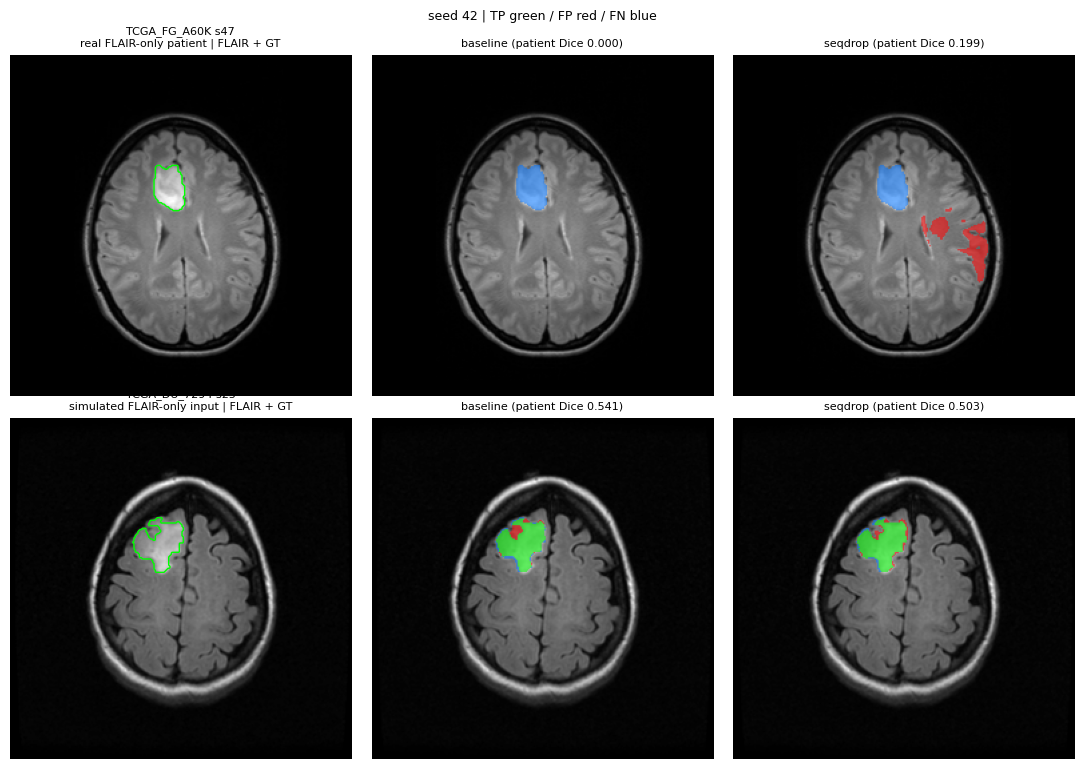

In [7]:
# ===== Cell 7: side-by-side figure (seed 42): baseline vs seqdrop =====
ensure_state()
import matplotlib.pyplot as plt
LONG = f"{BASE}/stage3_eval_long.csv"
need_files(LONG, f"{BASE}/baseline_s42/best.pt", f"{BASE}/seqdrop_s42/best.pt", hint="Run Cell 6 first.")
dev = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
mb = L.load_model(f"{BASE}/baseline_s42", dev)
ms = L.load_model(f"{BASE}/seqdrop_s42", dev)

def case_probs(model, rows, chans):
    df_t = df.iloc[rows].reset_index(drop=True); x = imgs[rows].copy()
    for c in chans: x[..., c] = x[..., 1]
    ar = np.arange(len(rows))
    pr = L.predict_probs(model, x, msks[rows], L.patient_channel_stats(df_t, x), ar, dev)
    s, _, _ = L.evaluate(df_t, msks[rows], pr, ar, n_boot=1)
    return pr, s["patient_dice_mean"]

lg = pd.read_csv(LONG)
db = lg[(lg.config == "baseline") & (lg.seed == 42)].pivot(index="patient_id", columns="scenario", values="dice")
worst = (db["flair_only"] - db["original"]).idxmin()
cases = [("TCGA_FG_A60K", (), "real FLAIR-only patient"), (worst, (0, 2), "simulated FLAIR-only input")]
fig, ax = plt.subplots(len(cases), 3, figsize=(11, 3.9 * len(cases)), squeeze=False)
for r, (pid, chans, tag) in enumerate(cases):
    rows = np.where(df.patient_id == pid)[0]
    pb, d_b = case_probs(mb, rows, chans); ps, d_s = case_probs(ms, rows, chans)
    k = int(np.argmax(msks[rows].reshape(len(rows), -1).sum(1)))
    base = L._norm01(imgs[rows[k]][..., 1]); gt = msks[rows[k]].astype(bool)
    ax[r, 0].imshow(base, cmap="gray"); ax[r, 0].contour(gt, [0.5], colors="lime", linewidths=1)
    ax[r, 0].set_title(f"{pid} s{df.slice_idx.iloc[rows[k]]}\n{tag} | FLAIR + GT", fontsize=8)
    ax[r, 1].imshow(L._err_rgb(base, pb[k] >= 0.5, gt)); ax[r, 1].set_title(f"baseline (patient Dice {d_b:.3f})", fontsize=8)
    ax[r, 2].imshow(L._err_rgb(base, ps[k] >= 0.5, gt)); ax[r, 2].set_title(f"seqdrop (patient Dice {d_s:.3f})", fontsize=8)
for a in ax.ravel(): a.axis("off")
plt.suptitle("seed 42 | TP green / FP red / FN blue", fontsize=9)
plt.tight_layout(); plt.savefig(f"{BASE}/stage3_comparison.png", dpi=110); plt.show()
del mb, ms
if torch.cuda.is_available(): torch.cuda.empty_cache()

In [8]:
# ===== Cell 8: wrap-up =====
total = 0
for root, _, files in os.walk(WORK_DIR):
    for f in files:
        try: total += os.path.getsize(os.path.join(root, f))
        except OSError: pass
print(f"/kaggle/working holds {total / 1e9:.2f} GB (limit 20 GB). Key results are in {BASE}:")
for f in ("stage3_runs.csv", "stage3_eval_long.csv", "stage3_comparison.png"):
    print("  ", f, "OK" if os.path.exists(f"{BASE}/{f}") else "missing")
print("Everything finished. Interactive session: press 'Stop session' now so no GPU quota is wasted. "
      "To keep the results: Save Version (output is stored and can be attached as Input next time).")

/kaggle/working holds 1.41 GB (limit 20 GB). Key results are in /kaggle/working/runs/stage3:
   stage3_runs.csv OK
   stage3_eval_long.csv OK
   stage3_comparison.png OK
Everything finished. Interactive session: press 'Stop session' now so no GPU quota is wasted. To keep the results: Save Version (output is stored and can be attached as Input next time).


In [9]:
import os

path = "/kaggle/working/runs/stage3"

print("Folder exists:", os.path.exists(path))

if os.path.exists(path):
    print("Files:", os.listdir(path))
else:
    print("Stage3 folder not found")

Folder exists: True
Files: ['seqdrop_s43', 'baseline_s43.log', 'stage3_eval_long.csv', 'baseline_s42', 'seqdrop_s42.log', 'seqdrop_s44', 'baseline_s42.log', 'baseline_s44', 'baseline_s43', 'seqdrop_s44.log', 'stage3_runs.csv', 'stage3_comparison.png', 'baseline_s44.log', 'seqdrop_s43.log', 'seqdrop_s42', 'stage3_eval_signature.json']
